# Home Credit : scoring du risque de défaut de crédit
## Notebook 05 : modèle final, règle d'octroi, explications et équité

Les notebooks précédents ont construit une base d'environ 170 variables par client (table principale, bureau de crédit, historique chez Home Credit) et une référence par régression logistique. Ce dernier notebook :

1. entraîne un modèle de **gradient boosting** (LightGBM) et le compare à la régression logistique ;
2. évalue **une seule fois** les modèles retenus sur l'échantillon de test, mis de côté depuis le notebook 01 ;
3. transforme les probabilités en une **règle d'octroi** fondée sur les coûts ;
4. **explique** les décisions du modèle (valeurs SHAP), globalement et client par client ;
5. réalise un **audit d'équité** selon le sexe et l'âge ;
6. enregistre le modèle pour une future application.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import shap
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, confusion_matrix)
from sklearn.calibration import calibration_curve

sys.path.append(str(Path("..").resolve()))
from src.preparation import VARIABLES_EQUITE
from src.modelisation import pipeline_logistique, GRAINE, VALIDATION

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DOSSIER_TRAITEES = Path("../data/traitees")
DOSSIER_MODELES = Path("../modeles")
DOSSIER_MODELES.mkdir(exist_ok=True)

# 1. Assemblage de la base de modélisation

In [2]:
application = pd.read_parquet(DOSSIER_TRAITEES / "application_propre.parquet")
bureau = pd.read_parquet(DOSSIER_TRAITEES / "variables_bureau.parquet")
historique = pd.read_parquet(DOSSIER_TRAITEES / "variables_historique.parquet")
base = (application.merge(bureau, on="SK_ID_CURR", how="left", validate="one_to_one")
                   .merge(historique, on="SK_ID_CURR", how="left", validate="one_to_one"))

exclues = ["SK_ID_CURR", "TARGET", "echantillon"] + VARIABLES_EQUITE
qualitatives = [c for c in base.columns if c not in exclues and base[c].dtype.kind not in "biuf"]
numeriques = [c for c in base.columns if c not in exclues and c not in qualitatives]
for c in numeriques:
    base[c] = base[c].astype(float)

app = base[base["echantillon"] == "apprentissage"].reset_index(drop=True)
test = base[base["echantillon"] == "test"].reset_index(drop=True)
X_app, y_app = app[numeriques + qualitatives], app["TARGET"]
X_test, y_test = test[numeriques + qualitatives], test["TARGET"]

print(f"Apprentissage : {len(app):,} clients   Test : {len(test):,} clients".replace(",", " "))
print(f"{len(numeriques)} variables numériques, {len(qualitatives)} qualitatives")

Apprentissage : 246 008 clients   Test : 61 503 clients
142 variables numériques, 10 qualitatives


# 2. Gradient boosting (LightGBM)

## 2.1 Pourquoi un modèle à base d'arbres ?

La régression logistique suppose des effets **linéaires et additifs** (sur l'échelle du logit). L'exploration a pourtant montré des relations non monotones (la durée du prêt en dents de scie) et des interactions plausibles (un taux d'effort élevé n'a pas le même sens pour un retraité et pour un jeune salarié). Le gradient boosting construit des centaines de petits arbres de décision, chacun corrigeant les erreurs des précédents : il capte ces formes sans qu'on ait à les spécifier. Il gère aussi nativement les valeurs manquantes et les variables qualitatives, et il est insensible aux valeurs extrêmes.

## 2.2 Validation croisée

Le nombre d'arbres est choisi par **arrêt précoce** : on arrête d'ajouter des arbres quand la performance cesse de progresser. Pour que ce choix ne soit pas fait sur le pli d'évaluation (ce qui serait optimiste), on réserve à chaque fois 10 % de l'échantillon d'entraînement du pli pour l'arrêt précoce.

In [3]:
def preparer_lgb(X, categories=None):
    """Variables qualitatives en type catégoriel, avec les modalités apprises sur l'apprentissage."""
    X = X.copy()
    if categories is None:
        categories = {c: sorted(X[c].dropna().unique()) for c in qualitatives}
    for c in qualitatives:
        X[c] = pd.Categorical(X[c], categories=categories[c])
    return X, categories


PARAMETRES = dict(n_estimators=5000, learning_rate=0.03, num_leaves=31, min_child_samples=200,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.4, reg_lambda=5.0,
                  max_cat_to_onehot=8, cat_smooth=50, random_state=GRAINE, n_jobs=2, verbose=-1)


def entrainer_lgb(X, y, parametres=PARAMETRES):
    X_a, X_v, y_a, y_v = train_test_split(X, y, test_size=0.10, stratify=y, random_state=GRAINE)
    modele = lgb.LGBMClassifier(**parametres)
    modele.fit(X_a, y_a, eval_set=[(X_v, y_v)], eval_metric="auc",
               callbacks=[lgb.early_stopping(100, verbose=False)])
    return modele


debut = time.time()
proba_oof_lgb = np.zeros(len(app))
iterations, auc_plis = [], []
for pli, (i_a, i_v) in enumerate(VALIDATION.split(X_app, y_app), start=1):
    X_a, cats = preparer_lgb(X_app.iloc[i_a])
    X_v, _ = preparer_lgb(X_app.iloc[i_v], cats)
    modele = entrainer_lgb(X_a, y_app.iloc[i_a])
    proba_oof_lgb[i_v] = modele.predict_proba(X_v)[:, 1]
    iterations.append(modele.best_iteration_)
    auc_plis.append(roc_auc_score(y_app.iloc[i_v], proba_oof_lgb[i_v]))
    print(f"pli {pli} : AUC = {auc_plis[-1]:.4f}, {modele.best_iteration_} arbres ({time.time() - debut:.0f} s)")
print(f"\nAUC moyenne : {np.mean(auc_plis):.4f} (écart-type {np.std(auc_plis):.4f})")
del X_a, X_v, modele

pli 1 : AUC = 0.7897, 895 arbres (56 s)


pli 2 : AUC = 0.7880, 871 arbres (110 s)


pli 3 : AUC = 0.7882, 999 arbres (171 s)


pli 4 : AUC = 0.7878, 521 arbres (207 s)


pli 5 : AUC = 0.7882, 1106 arbres (274 s)

AUC moyenne : 0.7884 (écart-type 0.0007)


## 2.3 Comparaison avec la régression logistique

On calcule les prédictions hors-pli de la régression logistique complète (toutes les tables) sur les mêmes plis.

In [4]:
from sklearn.model_selection import cross_val_predict

debut = time.time()
logistique = pipeline_logistique(numeriques, qualitatives)
proba_oof_logit = cross_val_predict(logistique, X_app, y_app, cv=VALIDATION, method="predict_proba", n_jobs=1)[:, 1]
print(f"Logistique : {time.time() - debut:.0f} s")


def bilan(y, proba):
    auc = roc_auc_score(y, proba)
    return {"AUC": auc, "Gini": 2 * auc - 1, "AUC PR": average_precision_score(y, proba), "Brier": brier_score_loss(y, proba)}


pd.DataFrame({"Régression logistique": bilan(y_app, proba_oof_logit),
              "LightGBM": bilan(y_app, proba_oof_lgb)}).T.round(4)

Logistique : 104 s


,AUC,Gini,AUC PR,Brier
Régression logistique,0.7716,0.5431,0.2573,0.0670
LightGBM,0.7884,0.5767,0.2797,0.0659


**Lecture.** LightGBM fait nettement mieux que la régression logistique sur les mêmes plis :

| | AUC | Gini | AUC PR | Brier |
|---|---|---|---|---|
| Régression logistique | 0,772 | 0,543 | 0,257 | 0,0670 |
| LightGBM | **0,788** | **0,577** | **0,280** | **0,0659** |

Le gain (+1,7 point d'AUC, +3,4 points de Gini) est du même ordre que celui apporté par trois tables d'historique réunies. Il vient de ce que le modèle linéaire ne pouvait pas capter : les relations non monotones, les interactions et les seuils. LightGBM est aussi **très stable** d'un pli à l'autre (écart-type d'AUC de 0,0007). L'arrêt précoce retient entre 521 et 1 106 arbres selon le pli.

# 3. Évaluation finale sur l'échantillon de test

Les modèles sont réentraînés sur **tout** l'échantillon d'apprentissage, puis évalués une seule fois sur les 61 503 demandes du test, jamais utilisées jusqu'ici. Pour LightGBM, on fixe le nombre d'arbres à la moyenne obtenue en validation croisée, augmentée de 10 % (on entraîne sur 10 % de données en plus qu'en validation).

In [5]:
debut = time.time()
X_app_lgb, categories = preparer_lgb(X_app)
X_test_lgb, _ = preparer_lgb(X_test, categories)
nb_arbres = int(np.mean(iterations) * 1.1)
modele_lgb = lgb.LGBMClassifier(**(PARAMETRES | {"n_estimators": nb_arbres})).fit(X_app_lgb, y_app)
modele_logit = pipeline_logistique(numeriques, qualitatives).fit(X_app, y_app)
print(f"Entraînement final en {time.time() - debut:.0f} s ({nb_arbres} arbres)")

proba_test = {"Régression logistique": modele_logit.predict_proba(X_test)[:, 1],
              "LightGBM": modele_lgb.predict_proba(X_test_lgb)[:, 1]}
resultats_test = pd.DataFrame({nom: bilan(y_test, p) for nom, p in proba_test.items()}).T
resultats_test.round(4)

Entraînement final en 91 s (966 arbres)


,AUC,Gini,AUC PR,Brier
Régression logistique,0.7745,0.5489,0.2669,0.0666
LightGBM,0.7916,0.5831,0.2939,0.0653


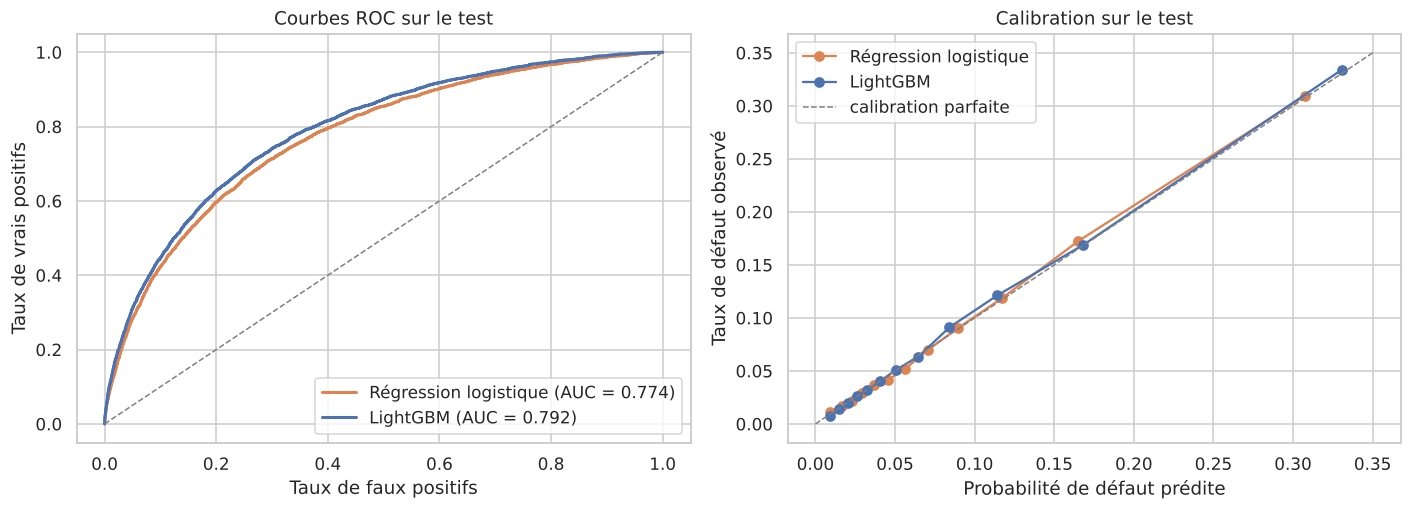

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for (nom, proba), couleur in zip(proba_test.items(), ["#DD8452", "#4C72B0"]):
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, lw=2, color=couleur, label=f"{nom} (AUC = {roc_auc_score(y_test, proba):.3f})")
    frac, moy = calibration_curve(y_test, proba, n_bins=12, strategy="quantile")
    axes[1].plot(moy, frac, marker="o", color=couleur, label=nom)
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
axes[0].set(xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs", title="Courbes ROC sur le test")
axes[0].legend(loc="lower right")
lim = max(axes[1].get_xlim()[1], axes[1].get_ylim()[1])
axes[1].plot([0, lim], [0, lim], ls="--", color="grey", lw=1, label="calibration parfaite")
axes[1].set(xlabel="Probabilité de défaut prédite", ylabel="Taux de défaut observé", title="Calibration sur le test")
axes[1].legend()
plt.tight_layout()
plt.show()

**Lecture.** Sur les 61 503 demandes jamais vues :
- **LightGBM atteint une AUC de 0,792 (Gini de 0,58)**, contre 0,774 pour la régression logistique. L'écart observé en validation croisée se confirme.
- Les performances sur le test sont même **légèrement supérieures** à celles de la validation croisée (0,792 contre 0,788) : le modèle n'a pas surappris, et l'estimation faite pendant la mise au point était fiable. Le léger écart s'explique par l'entraînement final sur 100 % de l'apprentissage, au lieu de 80 % en validation croisée.
- **Les deux modèles sont remarquablement bien calibrés** : les points suivent la diagonale jusqu'à 33 % de risque prédit. Quand LightGBM annonce 17 % de risque, 17 % des clients font effectivement défaut. C'est ce qui permet d'utiliser directement ces probabilités pour calculer des pertes attendues et fixer le seuil d'octroi.

# 4. De la probabilité à la décision : la règle d'octroi

Le modèle donne une probabilité de défaut ; la banque doit décider **accepter ou refuser**. Le seuil ne se choisit pas à 0,5 par habitude, mais en comparant les coûts des deux erreurs possibles :

| | Client qui rembourse | Client qui fait défaut |
|---|---|---|
| **Accepté** | gain : la marge sur le crédit | perte : une partie du capital non remboursé |
| **Refusé** | manque à gagner : la marge perdue | aucune perte |

Hypothèses de travail, à ajuster avec les équipes métier :
- **marge sur un bon client** : 10 % du montant prêté (intérêts et frais, nets du coût de financement) ;
- **perte sur un défaut** : 45 % du montant prêté. C'est la perte en cas de défaut (*LGD*) forfaitaire que prévoit la réglementation bâloise pour les créances non garanties ; elle tient compte de ce qui est récupéré après le défaut.

Un défaut coûte donc environ 4,5 fois ce que rapporte un bon client. Le seuil est choisi sur les **prédictions hors-pli de l'apprentissage**, puis appliqué tel quel au test.

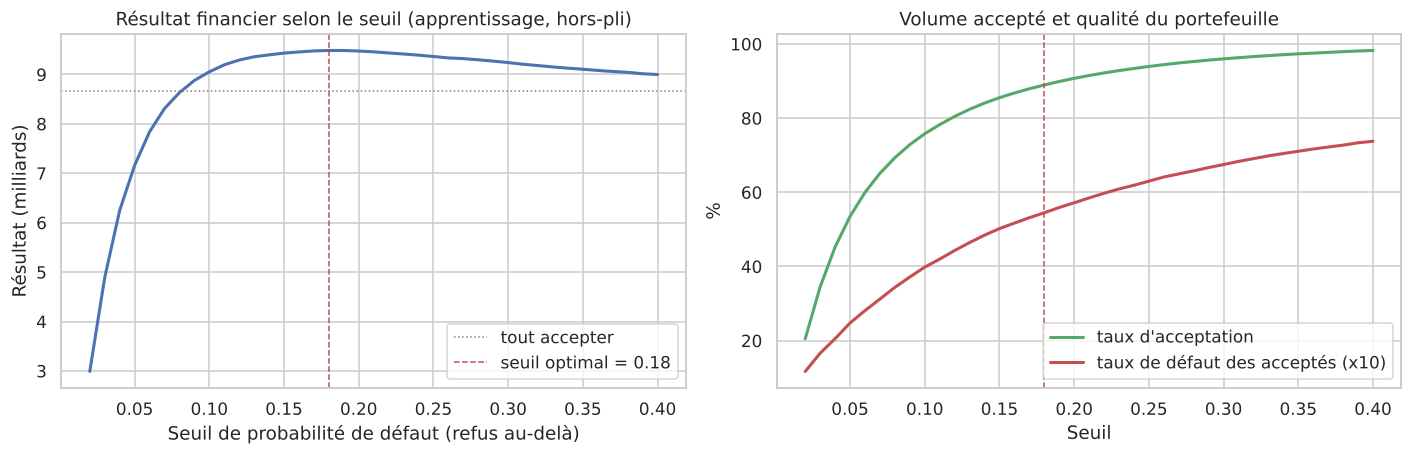

Seuil retenu : refus si la probabilité de défaut dépasse 0.18


In [7]:
MARGE, PERTE = 0.10, 0.45
montant_app = app["AMT_GOODS_PRICE"].fillna(app["AMT_GOODS_PRICE"].median()) * app["PART_FINANCEE"].fillna(1)
montant_test = test["AMT_GOODS_PRICE"].fillna(test["AMT_GOODS_PRICE"].median()) * test["PART_FINANCEE"].fillna(1)


def resultat_financier(y, proba, montant, seuil):
    accepte = proba < seuil
    gain = (MARGE * montant * ((y == 0) & accepte)).sum()
    perte = (PERTE * montant * ((y == 1) & accepte)).sum()
    return {"seuil": seuil, "taux_acceptation": accepte.mean(), "taux_defaut_acceptes": y[accepte].mean(),
            "resultat": gain - perte}


seuils = np.round(np.arange(0.02, 0.41, 0.01), 2)
courbe = pd.DataFrame([resultat_financier(y_app.values, proba_oof_lgb, montant_app.values, s) for s in seuils])
reference = resultat_financier(y_app.values, proba_oof_lgb, montant_app.values, 1.01)["resultat"]
SEUIL = float(courbe.loc[courbe["resultat"].idxmax(), "seuil"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(courbe["seuil"], courbe["resultat"] / 1e9, color="#4C72B0", lw=2)
axes[0].axhline(reference / 1e9, color="grey", ls=":", lw=1, label="tout accepter")
axes[0].axvline(SEUIL, color="#C44E52", ls="--", lw=1, label=f"seuil optimal = {SEUIL:.2f}")
axes[0].set(xlabel="Seuil de probabilité de défaut (refus au-delà)", ylabel="Résultat (milliards)",
            title="Résultat financier selon le seuil (apprentissage, hors-pli)")
axes[0].legend()
axes[1].plot(courbe["seuil"], courbe["taux_acceptation"] * 100, color="#55A868", lw=2, label="taux d'acceptation")
axes[1].plot(courbe["seuil"], courbe["taux_defaut_acceptes"] * 100 * 10, color="#C44E52", lw=2, label="taux de défaut des acceptés (x10)")
axes[1].axvline(SEUIL, color="#C44E52", ls="--", lw=1)
axes[1].set(xlabel="Seuil", ylabel="%", title="Volume accepté et qualité du portefeuille")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Seuil retenu : refus si la probabilité de défaut dépasse {SEUIL:.2f}")

In [8]:
lignes = []
for nom, proba in proba_test.items():
    r = resultat_financier(y_test.values, proba, montant_test.values, SEUIL if nom == "LightGBM" else SEUIL)
    lignes.append({"stratégie": f"{nom}, seuil {SEUIL:.2f}"} | r)
lignes.append({"stratégie": "Tout accepter"} | resultat_financier(y_test.values, proba_test["LightGBM"], montant_test.values, 1.01))
decision = pd.DataFrame(lignes).drop(columns="seuil").set_index("stratégie")
decision["resultat (millions)"] = decision.pop("resultat") / 1e6
decision.round(3)

,taux_acceptation,taux_defaut_acceptes,resultat (millions)
stratégie,,,
"Régression logistique, seuil 0.18",0.895,0.056,2343.430
"LightGBM, seuil 0.18",0.890,0.054,2371.014
Tout accepter,1.000,0.081,2150.429


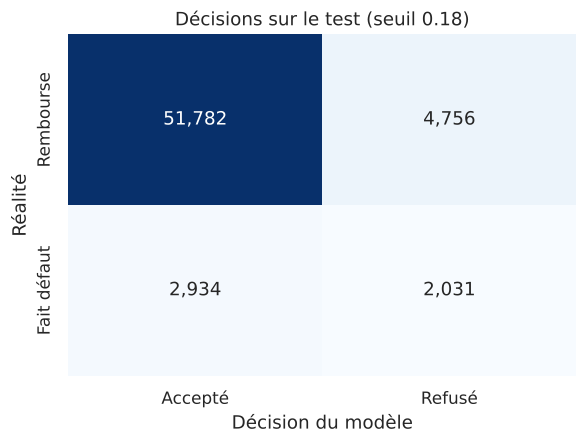

In [9]:
accepte = proba_test["LightGBM"] < SEUIL
mc = confusion_matrix(y_test, ~accepte)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(mc, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Accepté", "Refusé"], yticklabels=["Rembourse", "Fait défaut"])
ax.set(xlabel="Décision du modèle", ylabel="Réalité", title=f"Décisions sur le test (seuil {SEUIL:.2f})")
plt.tight_layout()
plt.show()

**Lecture.**
- **Le seuil optimal est de 18 %** : on refuse un crédit quand la probabilité de défaut dépasse 18 %. Avec un rapport perte / marge de 4,5, il faut en effet qu'un client ait plus d'une chance sur cinq ou six de faire défaut pour que le refuser rapporte plus que l'accepter. La courbe du résultat est **plate entre 12 % et 25 %** : la décision est robuste à une petite erreur sur le seuil.
- **Sur le test,** cette règle accepte 89 % des demandes et ramène le taux de défaut des clients acceptés de 8,1 % à **5,4 %**.
- **Le résultat financier progresse de 10 %** par rapport à « tout accepter » (2 371 millions contre 2 150). LightGBM fait aussi mieux que la régression logistique avec le même seuil (+28 millions).
- **La matrice de confusion** montre le compromis : parmi les 6 787 refus, 2 031 auraient fait défaut (30 %, soit près de 4 fois le taux moyen), mais 4 756 étaient de bons clients. Le modèle repère 41 % des défauts en refusant seulement 11 % des demandes.

**Limite :** le seuil dépend directement des hypothèses de marge (10 %) et de perte (45 %). Avec les vrais chiffres de la banque, il suffit de relancer ce calcul pour obtenir le seuil adapté.

# 5. Explication des décisions (valeurs SHAP)

Une banque doit pouvoir **justifier** un refus : auprès du client, qui a le droit de connaître les principaux motifs d'une décision automatisée (RGPD, article 22), et auprès du régulateur. Les valeurs SHAP décomposent chaque prédiction en contributions additives des variables, sur l'échelle du logit : la somme des contributions plus la valeur de base donne exactement la prédiction du modèle.

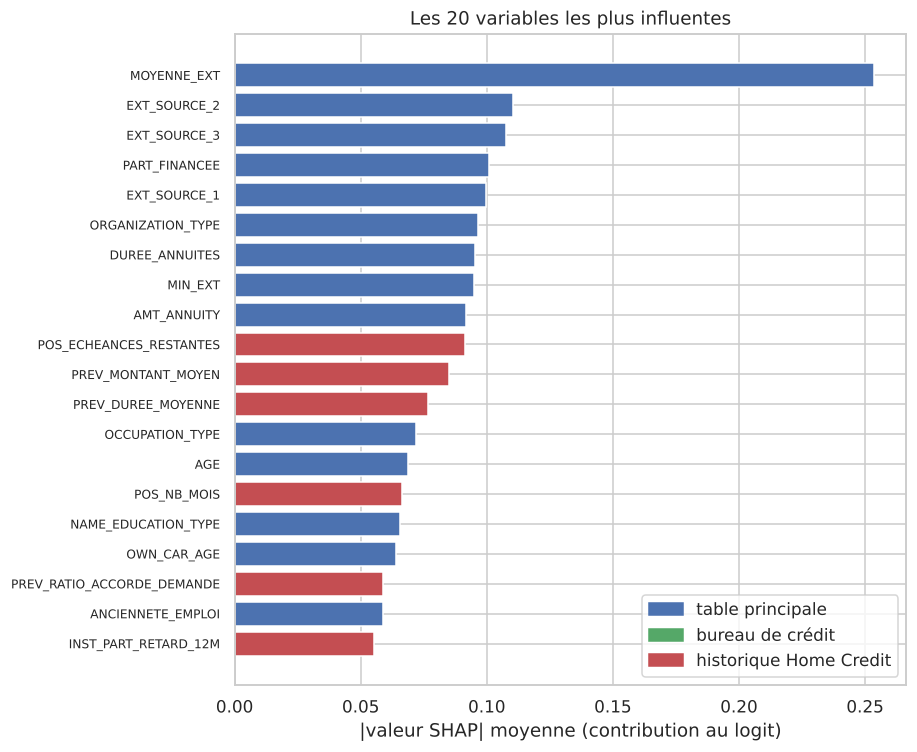

In [10]:
echantillon_shap = X_test_lgb.sample(5000, random_state=GRAINE)
explicateur = shap.TreeExplainer(modele_lgb)
valeurs_shap = explicateur(echantillon_shap)
if valeurs_shap.values.ndim == 3:
    valeurs_shap = valeurs_shap[:, :, 1]

importance = pd.Series(np.abs(valeurs_shap.values).mean(axis=0), index=echantillon_shap.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 7))
top = importance.head(20).iloc[::-1]
couleurs = ["#C44E52" if n.startswith(("INST", "PREV", "POS", "CB")) else "#55A868" if n.startswith("BUR")
            else "#4C72B0" for n in top.index]
ax.barh(top.index, top.values, color=couleurs)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#4C72B0", "#55A868", "#C44E52"]],
          labels=["table principale", "bureau de crédit", "historique Home Credit"], loc="lower right")
ax.set(xlabel="|valeur SHAP| moyenne (contribution au logit)", title="Les 20 variables les plus influentes")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

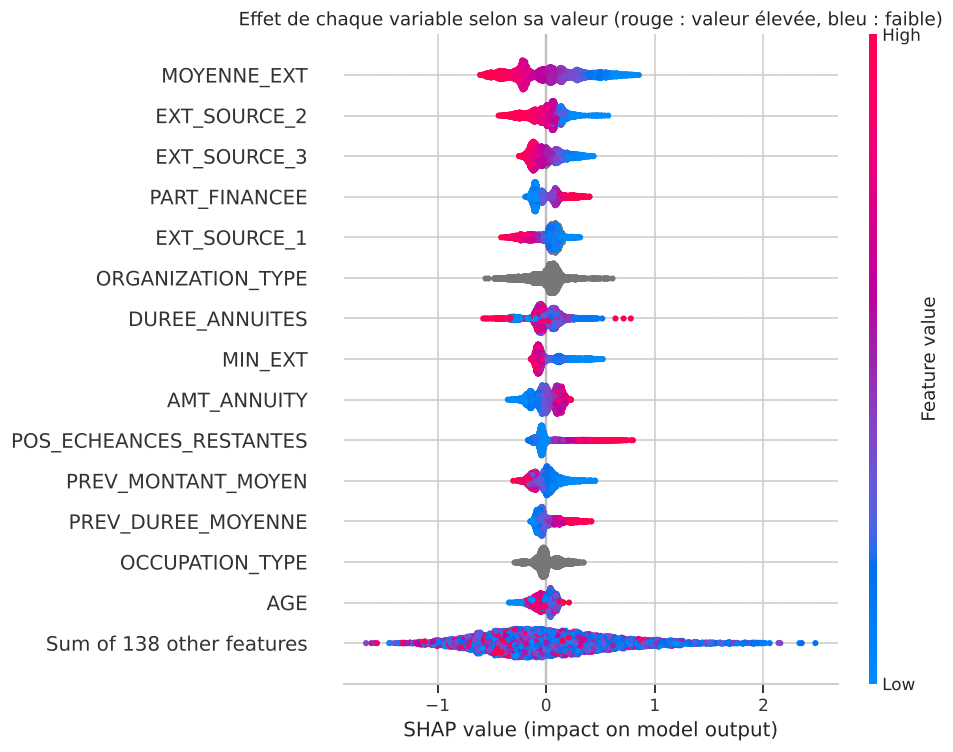

In [11]:
shap.plots.beeswarm(valeurs_shap, max_display=15, show=False)
plt.title("Effet de chaque variable selon sa valeur (rouge : valeur élevée, bleu : faible)")
plt.gcf().set_size_inches(9, 7)
plt.tight_layout()
plt.show()

**Lecture.**
- **La moyenne des scores externes domine**, loin devant toutes les autres variables (contribution moyenne de 0,25 au logit). C'est la variable construite dans le notebook 02 à partir de l'exploration.
- Viennent ensuite **les caractéristiques du crédit** (part financée, durée, annuité), **l'employeur** et **l'historique chez Home Credit** : échéances restant à payer sur des prêts en cours, montant et durée des crédits passés, rapport entre montant accordé et demandé, retards de paiement des 12 derniers mois.
- **Aucune variable du bureau de crédit** n'apparaît dans les 20 premières, ce qui est cohérent avec son faible apport mesuré dans le notebook 03.

Le nuage de points (*beeswarm*) confirme le sens des effets. Des scores externes faibles (en bleu) augmentent le risque. Une part financée élevée (le crédit dépasse le prix du bien) l'augmente aussi. Un client qui a encore beaucoup d'échéances à payer sur un prêt Home Credit en cours est plus risqué. À l'inverse, un client à qui Home Credit a déjà accordé des crédits importants l'est moins.

## 5.1 Expliquer un refus

On prend un client du test refusé par le modèle et on affiche les variables qui ont le plus pesé dans la décision.

Probabilité de défaut prédite : 27.5% (seuil : 18%)


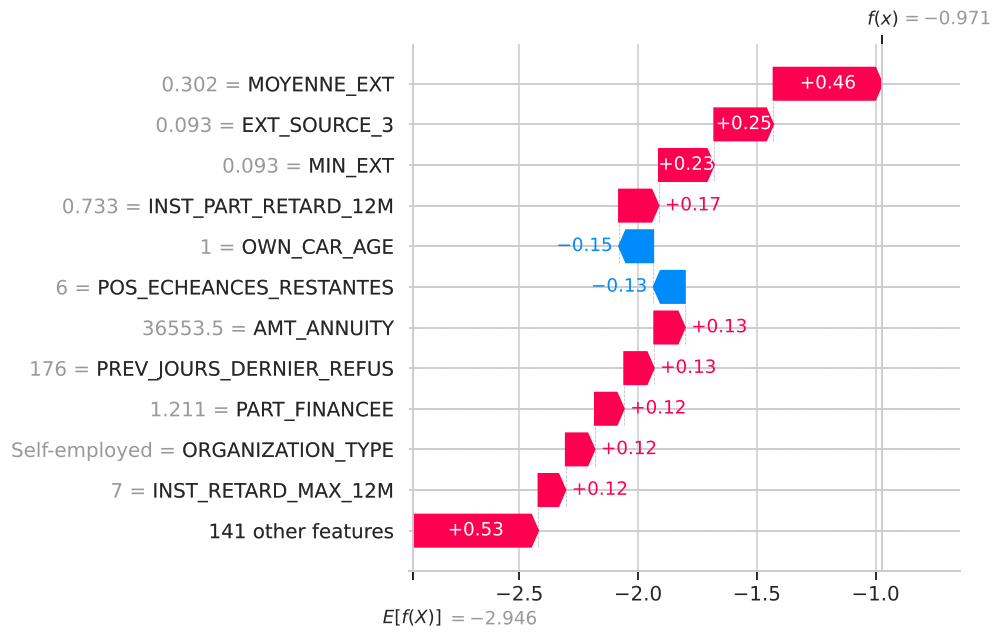

In [12]:
proba_echantillon = modele_lgb.predict_proba(echantillon_shap)[:, 1]
refuses = np.where(proba_echantillon >= SEUIL)[0]
client = refuses[np.argsort(proba_echantillon[refuses])[len(refuses) // 2]]
print(f"Probabilité de défaut prédite : {proba_echantillon[client]:.1%} (seuil : {SEUIL:.0%})")

shap.plots.waterfall(valeurs_shap[client], max_display=12, show=False)
plt.gcf().set_size_inches(9, 6)
plt.tight_layout()
plt.show()

In [13]:
def motifs_refus(i, n=4):
    contributions = pd.Series(valeurs_shap.values[i], index=echantillon_shap.columns)
    principaux = contributions.sort_values(ascending=False).head(n)
    return pd.DataFrame({"valeur du client": echantillon_shap.iloc[i][principaux.index].values,
                         "contribution au risque": principaux.values.round(3)}, index=principaux.index)


motifs_refus(client)

,valeur du client,contribution au risque
MOYENNE_EXT,0.302011,0.459
EXT_SOURCE_3,0.092617,0.250
MIN_EXT,0.092617,0.233
INST_PART_RETARD_12M,0.733333,0.168


**Lecture.** Ce client a une probabilité de défaut de 27,5 %, au-dessus du seuil de 18 %. On part du risque moyen (−2,95 sur l'échelle du logit) pour arriver à −0,97, et le graphique montre ce qui a fait monter son risque :
1. des **scores de crédit externes faibles** (moyenne de 0,30, et seulement 0,09 pour `EXT_SOURCE_3`) ;
2. des **retards de paiement récents** : 73 % de ses échéances des 12 derniers mois ont été payées en retard, avec un retard maximal de 7 jours ;
3. un **refus récent** chez Home Credit, il y a 176 jours ;
4. un **statut d'indépendant** et un crédit qui finance 121 % du prix du bien.

Deux éléments jouent en sa faveur : une voiture récente et un prêt en cours presque terminé (6 échéances restantes).

C'est exactement la forme d'explication qu'une banque doit pouvoir fournir. Elle se traduit directement en motifs compréhensibles : « historique de crédit défavorable, retards de paiement récents, demande récente refusée ».

# 6. Audit d'équité

Le sexe et la situation familiale ont été **exclus** du modèle. On vérifie maintenant si le modèle traite néanmoins différemment les groupes, à travers d'autres variables qui leur seraient liées. On compare, sur le test : le taux de refus, le taux de défaut réel, et les deux taux d'erreur.
- **Taux de faux refus** : part des bons clients refusés à tort.
- **Taux de défauts acceptés** : part des clients défaillants que le modèle a acceptés.

In [14]:
def audit(groupe):
    t = pd.DataFrame({"groupe": groupe, "defaut": y_test.values, "refus": ~accepte})
    lignes = {}
    for g, d in t.groupby("groupe", observed=True):
        lignes[g] = {"clients": len(d), "taux de défaut réel": d["defaut"].mean(), "taux de refus": d["refus"].mean(),
                     "taux de faux refus": d.loc[d["defaut"] == 0, "refus"].mean(),
                     "taux de défauts acceptés": 1 - d.loc[d["defaut"] == 1, "refus"].mean()}
    return pd.DataFrame(lignes).T


print("Selon le sexe")
display(audit(test["CODE_GENDER"]).round(3))
print("Selon l'âge")
display(audit(pd.cut(test["AGE"], [18, 30, 45, 60, 100], labels=["moins de 30 ans", "30-45 ans", "45-60 ans", "plus de 60 ans"])).round(3))

Selon le sexe


,clients,taux de défaut réel,taux de refus,taux de faux refus,taux de défauts acceptés
F,40561.0,0.070,0.094,0.073,0.624
M,20940.0,0.102,0.142,0.107,0.547


Selon l'âge


,clients,taux de défaut réel,taux de refus,taux de faux refus,taux de défauts acceptés
moins de 30 ans,8905.0,0.113,0.195,0.158,0.509
30-45 ans,24744.0,0.088,0.131,0.100,0.548
45-60 ans,20666.0,0.069,0.076,0.056,0.657
plus de 60 ans,7188.0,0.050,0.033,0.025,0.824


**Lecture.**

**Selon le sexe.** Le sexe n'est pas une variable du modèle, et pourtant les hommes sont refusés plus souvent (14,2 % contre 9,4 %). Une partie de cet écart reflète une différence de risque réelle (10,2 % de défaut contre 7,0 %). Mais à comportement de remboursement égal, **un homme bon payeur a aussi plus de chances d'être refusé à tort** (10,7 % contre 7,3 %). Le modèle retrouve donc indirectement le sexe à travers des variables qui lui sont liées, comme la profession, le secteur d'activité ou la possession d'une voiture.

Avec la règle des quatre cinquièmes, souvent utilisée pour repérer un effet discriminatoire, le rapport des taux d'acceptation est de 85,8 % / 90,6 % = 0,95, au-dessus du seuil de 0,8. L'écart n'est donc pas considéré comme discriminatoire selon ce critère, mais il doit être **documenté et suivi**.

**Selon l'âge.** L'écart est beaucoup plus marqué : 19,5 % de refus chez les moins de 30 ans contre 3,3 % chez les plus de 60 ans, et un bon payeur de moins de 30 ans est refusé à tort 6 fois plus souvent (15,8 % contre 2,5 %). L'âge est ici utilisé directement par le modèle, et l'écart de risque réel est important (11,3 % contre 5,0 %). C'est une pratique courante en crédit, mais elle doit être justifiée.

**Pistes :** mesurer ce que coûterait en performance un modèle sans la variable d'âge, et suivre ces indicateurs dans le temps une fois le modèle en production.

# 7. Enregistrement du modèle

On enregistre tout ce qu'il faut pour scorer un nouveau client : le modèle, la liste et l'ordre des variables, les modalités des variables qualitatives et le seuil d'octroi.

In [15]:
artefact = {"modele": modele_lgb, "numeriques": numeriques, "qualitatives": qualitatives,
            "categories": categories, "seuil": SEUIL, "marge": MARGE, "perte": PERTE}
joblib.dump(artefact, DOSSIER_MODELES / "modele_lightgbm.joblib")
print("Modèle enregistré :", DOSSIER_MODELES / "modele_lightgbm.joblib")

Modèle enregistré : ../modeles/modele_lightgbm.joblib


# 8. Conclusion

## Résultats

| Étape | AUC | Gini |
|---|---|---|
| Scores externes seuls | 0,717 | 0,43 |
| Régression logistique, table principale | 0,747 | 0,49 |
| Régression logistique, toutes les tables | 0,772 | 0,54 |
| **LightGBM, toutes les tables (test)** | **0,792** | **0,58** |

1. **Les données** : 7 tables relationnelles, 58 millions de lignes, résumées en SQL (DuckDB) en environ 150 variables par client.
2. **L'information** : l'historique propre à Home Credit apporte trois fois plus que le bureau de crédit externe.
3. **Le modèle** : LightGBM gagne encore 2 points d'AUC sur la régression logistique. Ses probabilités sont bien calibrées et sa performance est confirmée sur un échantillon de test jamais utilisé.
4. **La décision** : une règle d'octroi fondée sur les coûts (refus au-delà de 18 % de risque) accepte 89 % des demandes, réduit le taux de défaut des acceptés de 8,1 % à 5,4 % et améliore le résultat de 10 % par rapport à une acceptation systématique.
5. **La transparence** : chaque décision est expliquée par ses principaux facteurs (SHAP), et un audit d'équité documente les écarts selon le sexe et l'âge.

## Limites

- **Biais de sélection** : le modèle n'est entraîné que sur des clients à qui Home Credit a accordé un crédit. On ne sait pas comment auraient remboursé les clients refusés par le passé. En banque, ce problème est traité par des techniques d'*inférence des refusés* (*reject inference*).
- **Hypothèses de coût** : la marge de 10 % et la perte de 45 % sont des ordres de grandeur. Le seuil doit être recalculé avec les vrais paramètres de la banque.
- **Découpage aléatoire** : faute de date de demande dans les données, le test n'est pas postérieur à l'apprentissage. En production, il faudrait valider le modèle sur une période plus récente et suivre sa stabilité dans le temps.
- **Réglage limité** : les paramètres de LightGBM ont été fixés à des valeurs raisonnables, sans recherche approfondie. Une optimisation pourrait faire gagner quelques millièmes d'AUC.

## Pistes

- Une application Streamlit qui score un client, affiche sa probabilité de défaut, la décision et ses principaux motifs.
- Un modèle sans la variable d'âge, pour mesurer le coût de l'équité.
- Une grille de score complète intégrant les variables d'historique, pour les équipes qui préfèrent un barème en points.